
# DNA Sequence Generation using an LSTM (HBB gene / Sickle Cell Disease)

# GOAL:
#   Demonstrate that an LSTM can be used for generative modelling of biological  sequences (DNA), not just text. DNA is treated like character-level text
#   with a 4-letter vocabulary: A, C, G, T.
#<br>

# DATA :
#   - "normal" : real human HBB mRNA reference sequence, NCBI accession
#                NM_000518, downloaded via Biopython's Entrez.
#   - "sickle" : SYNTHETIC. Created by editing the normal sequence at codon 6
#                (GAG -> GTG, Glu -> Val), the known HbS point mutation.
#   No real patient data is used. The dataset is tiny (~600 bases per
#   sequence), so results are a proof of concept, not a clinical model.
# <br>

# METHOD:
#   1. Slide a window of SEQ_LEN bases over each sequence; predict the next base.
#   2. Train a single-layer LSTM (one-hot input -> softmax over A/C/G/T).
#   3. Generate new sequences base-by-base with temperature sampling.
#   4. Evaluate: k-mer statistics, GC content, copying from training data,
#      and similarity to the sickle/normal codon-6 motifs.
# <br>

# KNOWN LIMITATIONS:
#   - Overlapping windows from one gene => very little independent data.
#   - Validation accuracy is expected to stay near chance (0.25): the model
#     memorizes rather than generalizes.
#   - Generated sequences are not biologically validated.


In [1]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 23.2 MB/s  0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from itertools import product
from Bio import Entrez, SeqIO
from tensorflow.keras import layers, models, callbacks
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)


# 1. Data: HBB mRNA reference + sickle variant (codon 6 GAG -> GTG)

In [3]:

Entrez.email = "joyita.nandan@msds.christuniversity.in"
rec = SeqIO.read(Entrez.efetch(db="nucleotide", id="NM_000518",
                               rettype="fasta", retmode="text"), "fasta")
normal = str(rec.seq).upper()
NORMAL_MOTIF, SICKLE_MOTIF = "CCTGAGGAG", "CCTGTGGAG"   # codon 6 region
i = normal.find(NORMAL_MOTIF)
assert i != -1, "codon-6 motif not found"
sickle = normal[:i] + SICKLE_MOTIF + normal[i + len(NORMAL_MOTIF):]  # SYNTHETIC
print(f"Sequence length: {len(normal)} | codon-6 motif at index {i}")

chars = "ACGT"
c2i = {c: k for k, c in enumerate(chars)}
SEQ_LEN = 40

def make_windows(seq):
    X, y = [], []
    for s in range(len(seq) - SEQ_LEN):
        X.append([c2i[c] for c in seq[s:s + SEQ_LEN]])
        y.append(c2i[seq[s + SEQ_LEN]])
    return np.array(X), np.array(y)

Xn, yn = make_windows(normal)
Xs, ys = make_windows(sickle)
X = np.eye(4)[np.concatenate([Xn, Xs])]          # one-hot -> (N, 40, 4)
y = np.concatenate([yn, ys])

# Positional split (not random) so validation windows are not near-duplicates
# of training windows. Last 20% of each sequence is held out.
cut = int(0.8 * len(Xn))
tr = np.r_[0:cut, len(Xn):len(Xn) + cut]
va = np.r_[cut:len(Xn), len(Xn) + cut:len(X)]

# Baselines for context
chance = 0.25
majority = np.bincount(y[va]).max() / len(va)
print(f"Baselines on val set -> chance: {chance:.2f} | majority-class: {majority:.2f}")

Sequence length: 628 | codon-6 motif at index 65
Baselines on val set -> chance: 0.25 | majority-class: 0.35


# 2. MODEL

Epoch 1/60
30/30 - 5s - 156ms/step - accuracy: 0.2894 - loss: 1.3786 - val_accuracy: 0.2458 - val_loss: 1.4168
Epoch 2/60
30/30 - 0s - 10ms/step - accuracy: 0.3404 - loss: 1.3608 - val_accuracy: 0.2034 - val_loss: 1.4352
Epoch 3/60
30/30 - 0s - 10ms/step - accuracy: 0.3596 - loss: 1.3528 - val_accuracy: 0.2034 - val_loss: 1.4435
Epoch 4/60
30/30 - 0s - 10ms/step - accuracy: 0.3926 - loss: 1.3404 - val_accuracy: 0.2119 - val_loss: 1.4511
Epoch 5/60
30/30 - 0s - 10ms/step - accuracy: 0.3862 - loss: 1.3274 - val_accuracy: 0.1949 - val_loss: 1.4328
Epoch 6/60
30/30 - 0s - 10ms/step - accuracy: 0.3851 - loss: 1.3189 - val_accuracy: 0.1949 - val_loss: 1.4971
Epoch 7/60
30/30 - 0s - 10ms/step - accuracy: 0.3989 - loss: 1.3076 - val_accuracy: 0.1949 - val_loss: 1.4775
Epoch 8/60
30/30 - 0s - 10ms/step - accuracy: 0.3936 - loss: 1.3003 - val_accuracy: 0.1780 - val_loss: 1.5023
Epoch 9/60
30/30 - 0s - 16ms/step - accuracy: 0.3936 - loss: 1.2860 - val_accuracy: 0.1949 - val_loss: 1.5481


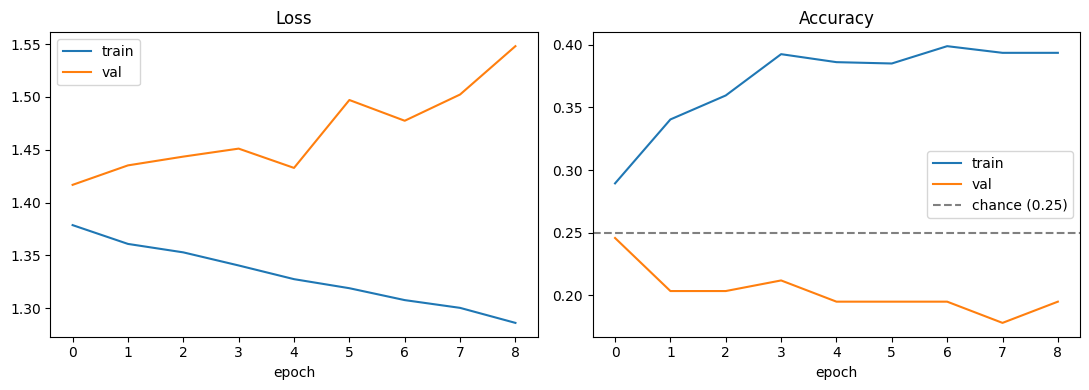

In [4]:
model = models.Sequential([
    layers.Input((SEQ_LEN, 4)),
    layers.LSTM(128),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
])
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                     restore_best_weights=True)
history = model.fit(X[tr], y[tr], validation_data=(X[va], y[va]),
                    epochs=60, batch_size=32, callbacks=[early_stop], verbose=2)

# Training curves: a widening train/val gap = overfitting
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].axhline(chance, ls="--", c="gray", label="chance (0.25)")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()


# 3. GENERATION

In [5]:
def sample(probs, temp):
    p = np.log(probs + 1e-9) / temp
    p = np.exp(p) / np.exp(p).sum()
    return np.random.choice(4, p=p)

def generate(seed, length=200, temp=0.8):
    out = list(seed)
    for _ in range(length):
        x = np.eye(4)[[c2i[c] for c in out[-SEQ_LEN:]]][None]
        probs = model(x, training=False).numpy()[0]
        out.append(chars[sample(probs, temp)])
    return "".join(out)

# 4. EVALUATION

In [6]:
def kmer_freq(s, k):
    c = Counter(s[j:j + k] for j in range(len(s) - k + 1))
    n = max(1, len(s) - k + 1)
    return np.array([c["".join(m)] for m in product(chars, repeat=k)]) / n

def gc_content(s):
    return (s.count("G") + s.count("C")) / len(s)

def min_mismatches(seq, motif):
    """Smallest Hamming distance between motif and any window of seq."""
    L = len(motif)
    return min(sum(a != b for a, b in zip(seq[j:j + L], motif))
               for j in range(len(seq) - L + 1))

train_text = normal + sickle
rows, all_seqs = [], []
for temp in [0.5, 0.8, 1.0, 1.2]:
    for n in range(3):                                   # 3 sequences per temp
        g = generate(normal[:SEQ_LEN], length=200, temp=temp)
        all_seqs.append((f"gen_T{temp}_{n}", g))
        rows.append({
            "temp": temp,
            "3mer_corr": np.corrcoef(kmer_freq(g, 3), kmer_freq(normal, 3))[0, 1],
            "4mer_corr": np.corrcoef(kmer_freq(g, 4), kmer_freq(normal, 4))[0, 1],
            "GC": gc_content(g),
            "copied_frac": np.mean([g[j:j + SEQ_LEN] in train_text
                                    for j in range(len(g) - SEQ_LEN)]),
            "HbS_mismatch": min_mismatches(g, SICKLE_MOTIF),
            "normal_mismatch": min_mismatches(g, NORMAL_MOTIF),
        })

results = pd.DataFrame(rows).groupby("temp").mean().round(3)
print(f"\nReference GC content (normal HBB): {gc_content(normal):.3f}")
print("Mean metrics per temperature (mismatch = 0 means exact motif found):")
print(results)

# Save generated sequences for the repo
with open("generated_sequences.fasta", "w") as f:
    for name, s in all_seqs:
        f.write(f">{name}\n{s}\n")


Reference GC content (normal HBB): 0.513
Mean metrics per temperature (mismatch = 0 means exact motif found):
      3mer_corr  4mer_corr     GC  copied_frac  HbS_mismatch  normal_mismatch
temp                                                                         
0.5       0.399      0.250  0.524        0.007         2.333            2.667
0.8       0.259      0.166  0.514        0.008         3.000            2.667
1.0       0.206      0.116  0.528        0.010         2.333            2.333
1.2       0.498      0.284  0.518        0.005         2.333            3.000


In [7]:
# Baseline: how many mismatches does a RANDOM sequence give?
def random_seq(n=240):
    return "".join(np.random.choice(list(chars), n))

base_hbs = np.mean([min_mismatches(random_seq(), SICKLE_MOTIF) for _ in range(200)])
base_nor = np.mean([min_mismatches(random_seq(), NORMAL_MOTIF) for _ in range(200)])
print(f"Random-sequence baseline -> HbS mismatch: {base_hbs:.2f} | normal mismatch: {base_nor:.2f}")

# Baseline: does the LSTM beat a simple 4-mer Markov chain on val data?
k = 4
counts = {}
for seq in (normal[:int(0.8*len(normal))], sickle[:int(0.8*len(sickle))]):
    for j in range(len(seq) - k):
        counts.setdefault(seq[j:j+k], Counter())[seq[j+k]] += 1
hits = tot = 0
for seq in (normal[int(0.8*len(normal)):], sickle[int(0.8*len(sickle)):]):
    for j in range(len(seq) - k):
        ctx = seq[j:j+k]
        if ctx in counts:
            hits += counts[ctx].most_common(1)[0][0] == seq[j+k]; tot += 1
print(f"Markov-4 val accuracy: {hits/max(tot,1):.3f} (on {tot} contexts seen in training)")

Random-sequence baseline -> HbS mismatch: 2.77 | normal mismatch: 2.77
Markov-4 val accuracy: 0.298 (on 188 contexts seen in training)


## CODON ADAPTATION INDEX (CAI)

In [8]:
!pip install python_codon_tables

import python_codon_tables as pct
from math import exp, log

# Codon Adaptation Index (Sharp & Li, 1987), target organism: Homo sapiens
table = pct.get_codons_table("h_sapiens_9606")      # {amino acid: {codon: frequency}}
# (if the name errors, run: print(pct.available_codon_tables_names))

# Relative adaptiveness w = codon frequency / frequency of the most-used synonymous codon
w = {}
for aa, codons in table.items():
    if aa == "*":
        continue
    best = max(codons.values())
    for c, f in codons.items():
        w[c] = f / best

STOPS = {"TAA", "TAG", "TGA"}
EXCLUDE = {"ATG", "TGG"}      # Met and Trp have a single codon, so no choice to score

def cai(cds):
    codons = [cds[j:j+3] for j in range(0, len(cds) - 2, 3)]
    ws = [max(w[c], 0.01) for c in codons if c in w and c not in EXCLUDE]
    return exp(sum(log(x) for x in ws) / len(ws)) if ws else float("nan")

#  Reading frame: the HBB coding sequence starts at ATG (MVHL...)
cds_start = normal.find("ATGGTGCATCTG")
assert cds_start >= 40, "CDS should start after the 40-base seed"   # seed is copied, not generated

def codons_of(seq):
    s = seq[cds_start:]
    return [s[j:j+3] for j in range(0, len(s) - 2, 3)]

def n_stops(seq):
    return sum(c in STOPS for c in codons_of(seq))

def orf_len(seq):             # codons before the first in-frame stop
    n = 0
    for c in codons_of(seq):
        if c in STOPS:
            break
        n += 1
    return n

# Reference values
ref_cds    = normal[cds_start:cds_start + 3 * orf_len(normal)]
sickle_cds = sickle[cds_start:cds_start + 3 * orf_len(sickle)]
print(f"CAI normal HBB CDS : {cai(ref_cds):.3f}  ({len(ref_cds)//3} codons)")
print(f"CAI sickle HBB CDS : {cai(sickle_cds):.3f}")

#  Generated sequences (g[cds_start:] is entirely model-generated)
rows = []
for name, g in all_seqs:
    rows.append({"temp": float(name.split("_")[1][1:]),
                 "CAI": cai(g[cds_start:]),
                 "stop_codons": n_stops(g),
                 "ORF_len_codons": orf_len(g)})
gen_df = pd.DataFrame(rows).groupby("temp").mean().round(3)

#  Random baseline: same length, uniform random bases
L = len(all_seqs[0][1])
rand = ["".join(np.random.choice(list("ACGT"), L)) for _ in range(200)]
print(f"\nRandom baseline -> CAI: {np.mean([cai(r[cds_start:]) for r in rand]):.3f} | "
      f"stop codons: {np.mean([n_stops(r) for r in rand]):.1f} | "
      f"ORF length: {np.mean([orf_len(r) for r in rand]):.1f} codons")
print("\nGenerated sequences (mean per temperature):")
print(gen_df)

CAI normal HBB CDS : 0.868  (147 codons)
CAI sickle HBB CDS : 0.868

Random baseline -> CAI: 0.659 | stop codons: 2.8 | ORF length: 21.4 codons

Generated sequences (mean per temperature):
        CAI  stop_codons  ORF_len_codons
temp                                    
0.5   0.675        2.000          16.667
0.8   0.644        2.000          38.333
1.0   0.615        2.000          35.667
1.2   0.691        2.667          12.667


## RUNNING MORE SEQUENCES PER TEMPERATURE AND REPORT SPREAD

In [9]:
rows = []
for temp in [0.5, 0.8, 1.0, 1.2]:
    for _ in range(20):
        g = generate(normal[:SEQ_LEN], length=200, temp=temp)
        rows.append({"temp": temp, "CAI": cai(g[cds_start:]),
                     "stops": n_stops(g), "ORF": orf_len(g)})
print(pd.DataFrame(rows).groupby("temp").agg(["mean", "std"]).round(3))

rand_cai = [cai(r[cds_start:]) for r in rand]
print(f"Random baseline CAI: {np.mean(rand_cai):.3f} ± {np.std(rand_cai):.3f}")

        CAI        stops           ORF        
       mean    std  mean    std   mean     std
temp                                          
0.5   0.662  0.032  2.15  1.040  22.20  18.679
0.8   0.652  0.052  1.90  1.373  29.20  22.512
1.0   0.660  0.035  2.25  1.293  21.15  16.259
1.2   0.658  0.036  2.75  1.164  20.10  11.392
Random baseline CAI: 0.659 ± 0.039


## Improved Model: Codon-Level LSTM on Many Real Globin Genes

The first model failed for two reasons: very little data (one ~600-base gene)
and no built-in reading frame (it predicted single bases). This section changes both:

- **More real data:** RefSeq globin (beta, alpha, delta, gamma) coding sequences
  from many mammals, downloaded from NCBI. Only clean CDSs are kept: start with ATG,
  one terminal stop codon, length divisible by 3, 120-200 codons, no duplicates.
- **Codon tokens:** the LSTM predicts the next codon (64 classes) from the previous
  20 codons, so every generated sequence is in frame.
- **Gene-level validation split:** whole genes are held out, so validation measures
  generalization, not memorization.
- **Evaluation:** CAI (human codon usage), length, terminal stop, and the highest
  codon-level identity to any training gene (compared against held-out real genes).

In [10]:
# Codon-level LSTM trained on real mammalian globin CDSs
# DATA : real RefSeq globin mRNAs (NCBI); CDS extracted, filtered, deduplicated.
#        No synthetic data in this section.
# MODEL: Embedding -> LSTM(128) -> Dense(64), next-codon prediction, context = 20 codons.
# SPLIT: 85/15 by gene (whole genes held out for validation).
# NOTE : in-frame ATG start and no internal stop codons are guaranteed by the
#        decoding rules (start token, minimum length), NOT learned by the model.
#        Learned quality is judged by CAI and identity to training genes.


import random, itertools
from Bio import Entrez, SeqIO
Entrez.email = "joyita.nandan@msds.christuniversity.in"

# 1. More real data: globin CDS from many mammals (RefSeq mRNAs)
term = ('("hemoglobin subunit beta"[Title] OR "hemoglobin subunit alpha"[Title] OR '
        '"hemoglobin subunit delta"[Title] OR "hemoglobin subunit gamma"[Title]) '
        'AND Mammalia[Organism] AND refseq[filter] AND biomol_mrna[PROP]')
ids = Entrez.read(Entrez.esearch(db="nucleotide", term=term, retmax=400))["IdList"]
print("records found:", len(ids))

cds_list = []
for s in range(0, len(ids), 100):
    h = Entrez.efetch(db="nucleotide", id=",".join(ids[s:s+100]), rettype="gb", retmode="text")
    for rec in SeqIO.parse(h, "genbank"):
        for f in rec.features:
            if f.type == "CDS":
                seq = f.extract(rec.seq)
                cds, prot = str(seq).upper(), str(seq.translate())
                if (len(cds) % 3 == 0 and cds.startswith("ATG") and prot.endswith("*")
                        and prot.count("*") == 1 and 120 <= len(cds)//3 <= 200
                        and set(cds) <= set("ACGT")):
                    cds_list.append(cds)
                break
cds_list = list(dict.fromkeys(cds_list))            # drop exact duplicates
print("usable CDS:", len(cds_list))

#  2. Codon-level tokens (reading frame built in)
codons = ["".join(c) for c in itertools.product("ACGT", repeat=3)]   # 64 codons
c2i = {c: k for k, c in enumerate(codons)}
START, K = 64, 20                                    # start/padding token, context in codons

def to_tokens(cds):
    return [c2i[cds[j:j+3]] for j in range(0, len(cds), 3)]

random.seed(42); random.shuffle(cds_list)
n_val = max(1, int(0.15 * len(cds_list)))
val_cds, train_cds = cds_list[:n_val], cds_list[n_val:]   # whole genes held out

def make_windows(seqs):
    X, y = [], []
    for cds in seqs:
        toks = [START] * K + to_tokens(cds)
        for s in range(len(toks) - K):
            X.append(toks[s:s+K]); y.append(toks[s+K])
    return np.array(X), np.array(y)

Xtr, ytr = make_windows(train_cds)
Xva, yva = make_windows(val_cds)
print("train/val windows:", Xtr.shape[0], Xva.shape[0],
      "| majority-codon val baseline:", round(np.bincount(yva).max() / len(yva), 3))

#  3. Model
codon_model = models.Sequential([
    layers.Input((K,)),
    layers.Embedding(65, 32),
    layers.LSTM(128),
    layers.Dropout(0.3),
    layers.Dense(64, activation="softmax"),
])
codon_model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
codon_model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=40, batch_size=64, verbose=2,
                callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                   restore_best_weights=True)])

# 4. Generation: starts from the START token, so nothing is copied as a seed
STOP_IDS = [c2i[c] for c in ("TAA", "TAG", "TGA")]

def generate_cds(temp=0.8, max_codons=200, min_codons=100):
    ctx, out = [START] * K, []
    for n in range(max_codons):
        probs = codon_model(np.array([ctx[-K:]]), training=False).numpy()[0]
        p = np.exp(np.log(probs + 1e-9) / temp)
        if n < min_codons:                           # decoding rule: no stop before min length
            p[STOP_IDS] = 0
        p /= p.sum()
        t = np.random.choice(64, p=p)
        out.append(t); ctx.append(t)
        if t in STOP_IDS:
            break
    return "".join(codons[t] for t in out)

#  5. Evaluation
def identity(a, b):                                  # positional codon-level identity
    L = min(len(a), len(b))
    return sum(x == y for x, y in zip(a[:L], b[:L])) / L

rows = []
for temp in [0.5, 0.8, 1.0, 1.2]:
    for _ in range(20):
        g = generate_cds(temp)
        rows.append({"temp": temp, "CAI": cai(g), "codons": len(g)//3,
                     "ends_with_stop": g[-3:] in STOPS,
                     "max_identity_to_train": max(identity(g, t) for t in train_cds)})
print(pd.DataFrame(rows).groupby("temp").mean().round(3))

print("\nHeld-out REAL globin genes -> CAI:", round(np.mean([cai(c) for c in val_cds]), 3),
      "| max identity to train:", round(np.mean([max(identity(c, t) for t in train_cds)
                                                  for c in val_cds]), 3))

records found: 400
usable CDS: 328
train/val windows: 40773 7152 | majority-codon val baseline: 0.093
Epoch 1/40
638/638 - 7s - 11ms/step - accuracy: 0.1687 - loss: 3.2756 - val_accuracy: 0.3687 - val_loss: 2.4920
Epoch 2/40
638/638 - 4s - 7ms/step - accuracy: 0.4970 - loss: 2.0253 - val_accuracy: 0.6532 - val_loss: 1.5020
Epoch 3/40
638/638 - 5s - 8ms/step - accuracy: 0.6605 - loss: 1.3935 - val_accuracy: 0.7163 - val_loss: 1.1748
Epoch 4/40
638/638 - 4s - 6ms/step - accuracy: 0.7097 - loss: 1.1463 - val_accuracy: 0.7366 - val_loss: 1.0404
Epoch 5/40
638/638 - 4s - 6ms/step - accuracy: 0.7320 - loss: 1.0206 - val_accuracy: 0.7455 - val_loss: 0.9846
Epoch 6/40
638/638 - 6s - 9ms/step - accuracy: 0.7488 - loss: 0.9396 - val_accuracy: 0.7557 - val_loss: 0.9429
Epoch 7/40
638/638 - 4s - 6ms/step - accuracy: 0.7619 - loss: 0.8862 - val_accuracy: 0.7589 - val_loss: 0.9211
Epoch 8/40
638/638 - 5s - 8ms/step - accuracy: 0.7721 - loss: 0.8387 - val_accuracy: 0.7659 - val_loss: 0.8963
Epoch 9/4

In [11]:
gens = [generate_cds(0.8) for _ in range(50)]
print("starts with ATG:", np.mean([g.startswith("ATG") for g in gens]))
print("median length, real vs generated (codons):",
      np.median([len(c)//3 for c in cds_list]), np.median([len(g)//3 for g in gens]))

starts with ATG: 1.0
median length, real vs generated (codons): 148.0 143.0


## Conclusion

Two LSTM generators were compared.

**Model 1: base-level LSTM, one HBB gene + one synthetic sickle variant
(628 bases).** It did not generalize. Training accuracy rose from 0.29 to
0.40, but validation accuracy stayed at 0.18-0.25, below the majority-class
baseline (0.35), and validation loss (1.42-1.55) never beat a uniform guess
(ln 4 = 1.386), so early stopping kept the epoch-1 weights. A 4-base Markov
chain scored higher (0.298 on 188 validation contexts). Generated sequences
matched the reference GC content (0.514-0.528 vs 0.513), but their 3-mer
correlation (0.21-0.50) varied erratically with temperature, and their closest
match to the codon-6 motif (2.3-3.0 mismatches) was no better than random
sequence (2.77). Its CAI (0.652-0.662 over 20 sequences per temperature) was
indistinguishable from random DNA (0.659 ± 0.039), and it produced 1.9-2.8
in-frame stop codons per sequence (real HBB: 0). It learned base composition
only.

**Model 2: codon-level LSTM on 328 real mammalian globin CDSs, split by gene
(279 training, 49 held-out genes).** Next-codon validation accuracy plateaued
at ~0.80 against a majority-codon baseline of 0.093. Generated sequences
reached CAI 0.829-0.875, against 0.849 for held-out real globin genes and 0.659
for random DNA. At temperature 0.8 (best balance), CAI was 0.875, 90% of
sequences ended with a stop codon, the mean length was 149 codons (median 143
vs 148 for real genes), and 100% of 50 sequences started with ATG. Temperature
trades quality for diversity: at 1.2, CAI fell to 0.829 and only 55% of
sequences terminated. Identity to the nearest training gene fell from 0.973
(temperature 0.5) to 0.614 (temperature 1.2). At 0.5 it is slightly above that
of held-out real genes (0.962), so those sequences are near-copies of training
genes; at 0.8 (0.934) it is below it.

**Interpretation.** The first model failed because of too little data and no
reading-frame structure, not because of the LSTM itself. With many real
sequences and codon tokens, the same model family produces globin-like coding
sequences with realistic codon usage, start codons and termination.

**Caveats.** Orthologs of held-out genes remain in training, so validation
accuracy is optimistic. The reading frame is guaranteed by the codon tokens,
and the absence of internal stop codons comes from the generation procedure
(a minimum length and stopping at the first stop codon); the ATG start and
termination are learned. CAI uses the human codon table, although the training
genes come from many mammals, and it measures codon bias only, not protein
function. It cannot separate normal from sickle HBB (both 0.868). Identity is
a positional codon comparison without alignment. Model 2 generates generic
globin sequences, not sickle-specific ones, and no protein-level or
experimental validation was done.

**Future work.** Translate a sample of the generated sequences and check them
with BLASTp against known globins, and condition the model on a variant label
(HbA vs HbS, e.g. from ClinVar) to generate sickle-specific sequences.